In [4]:
# If TensorFlow is missing in your environment, run:
# %pip install tensorflow scikit-learn pandas matplotlib

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [5]:

DATA_FILE = "monthly-milk-production-pounds-p.csv"

# If the Kaggle CSV is in the notebook folder, use it.
# Otherwise use a public mirror of the same 1962-1975 milk series.
if os.path.exists(DATA_FILE):
    df = pd.read_csv(DATA_FILE)
    source_used = "Local Kaggle CSV"
else:
    DATA_URL = (
        "https://raw.githubusercontent.com/udacity/aind2-rnn/master/"
        "datasets/monthly-milk-production-pounds-p.csv"
    )
    df = pd.read_csv(DATA_URL)
    source_used = "Public mirror of the same dataset"

# Rename columns to the names required in the task
df.columns = ["Month", "Production"]

df["Month"] = pd.to_datetime(df["Month"], errors="coerce")
df["Production"] = pd.to_numeric(df["Production"], errors="coerce")

df = df.dropna(subset=["Month", "Production"])
df = df.set_index("Month").sort_index()
print("Source:", source_used)
print("Shape:", df.shape)
display(df.head())
display(df.tail())

Source: Public mirror of the same dataset
Shape: (168, 1)


,Production
Month,
1962-01-01,589.0
1962-02-01,561.0
1962-03-01,640.0
1962-04-01,656.0
1962-05-01,727.0


,Production
Month,
1975-08-01,858.0
1975-09-01,817.0
1975-10-01,827.0
1975-11-01,797.0
1975-12-01,843.0


Number of observations: 168
Expected observations: 168
Index is monthly: True
Missing values: 0


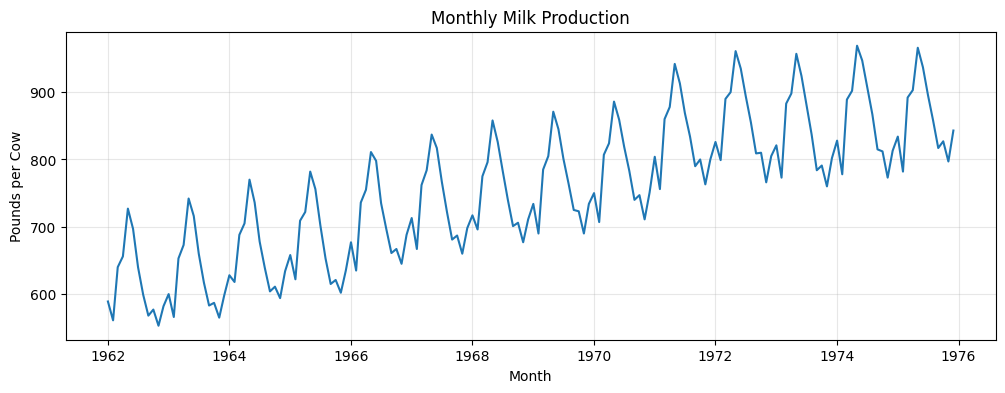

In [6]:
# Verify monthly sampling and the expected 168 observations
expected_index = pd.date_range(
    start="1962-01-01",
    end="1975-12-01",
    freq="MS"
)

print("Number of observations:", len(df))
print("Expected observations:", len(expected_index))
print("Index is monthly:", df.index.equals(expected_index))
print("Missing values:", df["Production"].isna().sum())

assert len(df) == 168
assert df.index.equals(expected_index)
assert df["Production"].notna().all()

# Plot the full series
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["Production"])
plt.title("Monthly Milk Production")
plt.xlabel("Month")
plt.ylabel("Pounds per Cow")
plt.grid(True, alpha=0.3)
plt.show()

In [7]:
train_size = 156
test_size = 12

train = df.iloc[:train_size].copy()
test = df.iloc[train_size:].copy()

scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler.fit_transform(train[["Production"]])
test_scaled = scaler.transform(test[["Production"]])

print("Training observations:", len(train))
print("Test observations:", len(test))
print("Train period:", train.index.min().date(), "to", train.index.max().date())
print("Test period:", test.index.min().date(), "to", test.index.max().date())

print("\nScaled train range:",
      train_scaled.min().round(4), "to", train_scaled.max().round(4))
print("Scaled test range:",
      test_scaled.min().round(4), "to", test_scaled.max().round(4))

Training observations: 156
Test observations: 12
Train period: 1962-01-01 to 1974-12-01
Test period: 1975-01-01 to 1975-12-01

Scaled train range: 0.0 to 1.0
Scaled test range: 0.5505 to 0.9928


In [8]:
sequence_length = 12
batch_size = 1

train_generator = TimeseriesGenerator(
    train_scaled,
    train_scaled,
    length=sequence_length,
    batch_size=batch_size
)

print("Input sequence length:", sequence_length)
print("Training sequences:", len(train_generator))

# Show one example
X_sample, y_sample = train_generator[0]
print("Example X shape:", X_sample.shape)
print("Example y shape:", y_sample.shape)

Input sequence length: 12
Training sequences: 144
Example X shape: (1, 12, 1)
Example y shape: (1, 1)


##  Build the LSTM model


In [9]:
model = keras.Sequential([
    layers.Input(shape=(sequence_length, 1)),
    layers.LSTM(64, activation="tanh"),
    layers.Dense(1)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0362
Epoch 2/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0263
Epoch 3/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0214
Epoch 4/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0199
Epoch 5/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0151
Epoch 6/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0064
Epoch 7/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0050
Epoch 8/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0058
Epoch 9/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0047
Epoch 10/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0046
Epoch 11/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0048
Epoch 12/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0042
Epoch 13/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0039
Epoch 14/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0054
Epoch 15/25
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - l

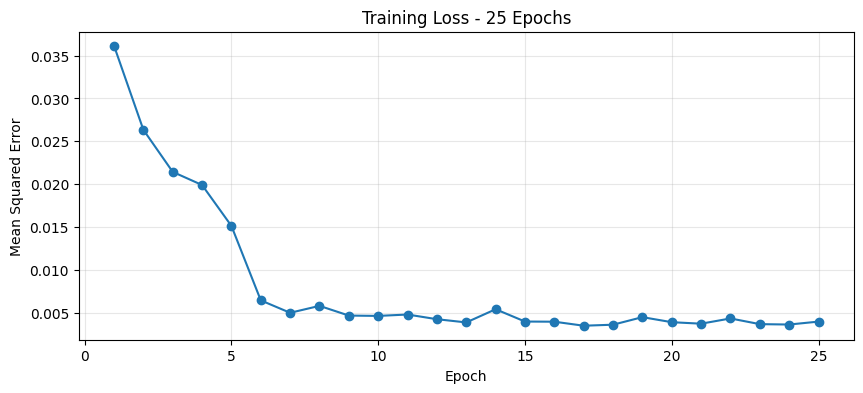

In [10]:
history = model.fit(
    train_generator,
    epochs=25,
    verbose=1
)

final_train_loss = history.history["loss"][-1]

print(f"Final training MSE loss: {final_train_loss:.6f}")

plt.figure(figsize=(10, 4))
plt.plot(range(1, 26), history.history["loss"], marker="o")
plt.title("Training Loss - 25 Epochs")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid(True, alpha=0.3)
plt.show()

## Recursive 12-month forecasting


In [11]:
# Start from the final 12 months of training data
rolling_window = train_scaled[-sequence_length:].reshape(1, sequence_length, 1)

forecast_scaled = []

for _ in range(test_size):
    next_pred = model.predict(rolling_window, verbose=0)[0, 0]
    forecast_scaled.append(next_pred)

    # Add prediction and remove the oldest observation
    new_window = np.append(
        rolling_window[0, :, 0][1:],
        next_pred
    )
    rolling_window = new_window.reshape(1, sequence_length, 1)

# Convert predictions back to pounds per cow
forecast = scaler.inverse_transform(
    np.array(forecast_scaled).reshape(-1, 1)
).flatten()

forecast_df = pd.DataFrame(
    {
        "Actual": test["Production"].values,
        "Forecast": forecast
    },
    index=test.index
)

display(forecast_df)

,Actual,Forecast
Month,,
1975-01-01,834.0,805.896484
1975-02-01,782.0,822.197632
1975-03-01,892.0,856.357666
1975-04-01,903.0,883.731934
1975-05-01,966.0,906.136169
1975-06-01,937.0,899.698059
1975-07-01,896.0,874.064148
1975-08-01,858.0,841.123840
1975-09-01,817.0,812.987061


##  Evaluation



In [12]:
actual = test["Production"].values

rmse = np.sqrt(mean_squared_error(actual, forecast))
mae = mean_absolute_error(actual, forecast)

print(f"Test RMSE: {rmse:.2f} pounds per cow")
print(f"Test MAE:  {mae:.2f} pounds per cow")

Test RMSE: 33.17 pounds per cow
Test MAE:  29.19 pounds per cow


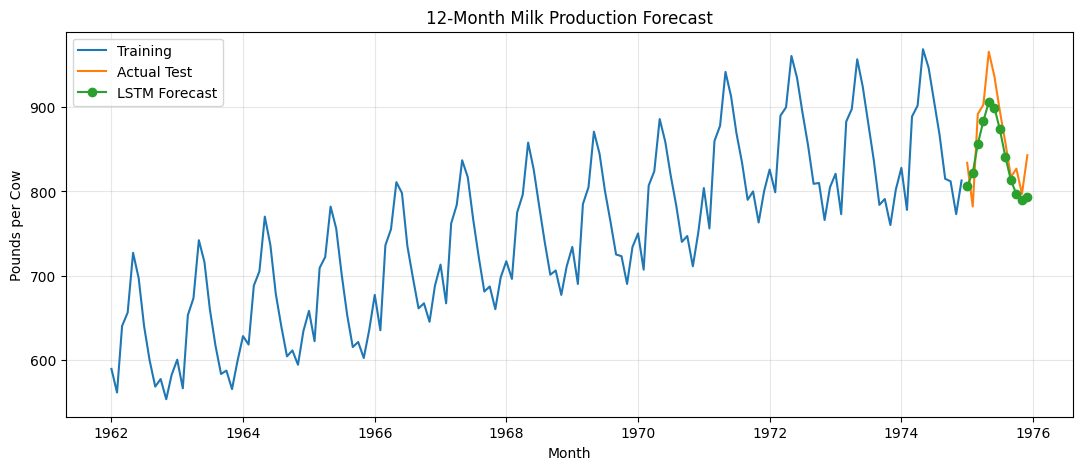

In [13]:
# Historical training series + actual test series + forecast
plt.figure(figsize=(13, 5))

plt.plot(train.index, train["Production"], label="Training")
plt.plot(test.index, test["Production"], label="Actual Test")
plt.plot(test.index, forecast, marker="o", label="LSTM Forecast")

plt.title("12-Month Milk Production Forecast")
plt.xlabel("Month")
plt.ylabel("Pounds per Cow")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

##  Performance summary


In [14]:
summary = pd.DataFrame({
    "Metric": [
        "Train observations",
        "Test observations",
        "Training sequences",
        "Input sequence length",
        "Epochs",
        "Final training MSE loss",
        "Test RMSE",
        "Test MAE"
    ],
    "Value": [
        len(train),
        len(test),
        len(train_generator),
        sequence_length,
        25,
        final_train_loss,
        rmse,
        mae
    ]
})

display(summary)

,Metric,Value
0,Train observations,156.000000
1,Test observations,12.000000
2,Training sequences,144.000000
3,Input sequence length,12.000000
4,Epochs,25.000000
5,Final training MSE loss,0.003952
6,Test RMSE,33.173994
7,Test MAE,29.186778


## Result

The pipeline follows the required chronological split, training-only scaling, 12-month sliding window, LSTM model, recursive 12-month forecast, inverse scaling, and RMSE/MAE evaluation.